# Data Preparation

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = sqlite3.connect("../data/hockey.db")
q = lambda sql: pd.read_sql(sql, con)
sql_file = lambda name: q(open(f"../sql/{name}").read())

sns.set_theme(style="whitegrid")

## 1. Data Integration

In this section we join tables so that each row carries information from more than one source. The rubric asks for two things, and we document both:

- **Matching entities between sources**: the key used to link two tables.
- **Conversion of formats**: turning raw fields into values a model can use.

### Coach profile

Query: [`sql/coach_profile.sql`](../sql/coach_profile.sql). One row per coach stint (`coachID`, `year`, `tmID`, `lgID`, `stint`), for **all leagues**, with the person's details from `Master`.

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `Coaches` | `Master` | `coachID` | birth date, `playerID`, `firstNHL` |

- We use a **left join** with `Coaches` as the driving table, so every coaching stint is kept even if the person were missing from `Master`.
- The result has **1,741 rows**, the same as `Coaches`. Every coach finds a match, and no `coachID` appears twice in `Master`, so the join neither loses nor duplicates rows.
- We keep **all leagues** (NHL, WHA, NHA, PCHA, WCHL), not only the NHL, so that a coach's experience can later include seasons coached outside the NHL. `lgID` is kept so we can filter to the NHL when building targets, and to join with `Teams` later.

#### Age at season start (format conversion)

`Master` stores the birth date in three separate columns (`birthYear`, `birthMon`, `birthDay`). We convert them into one number: the coach's **age at the start of the season**.

- **Reference date:** 1 August of `year`. In this dataset `year` is the season's starting year (2005 = 2005-06), so 1 August is before the season begins, and the age is known at prediction time.
- **Birthday rule:** if the birthday falls after 1 August, the coach has not turned the new age yet, so we subtract one year.
- **Missing month or day:** we assume 1 August, the same as the reference date. The age then becomes simply `year − birthYear`, which is wrong by at most one year.
- **Missing year:** the age is left missing (`<NA>`). It is not imputed here; that is handled in the *Missing values* section.

In [2]:
import datetime

coaches = sql_file("coach_profile.sql")

def calculate_age(row):
    if pd.isna(row["birthYear"]):
        return pd.NA
    
    birth_year = int(row["birthYear"])
    birth_month = 8 if pd.isna(row["birthMon"]) else int(row["birthMon"])
    birth_day = 1 if pd.isna(row["birthDay"]) else int(row["birthDay"])
    
    birth_date = datetime.date(
        birth_year,
        birth_month,
        birth_day
    )

    reference_date = datetime.date(
        int(row["year"]),
        8,
        1
    )

    age = reference_date.year - birth_date.year

    if (birth_date.month, birth_date.day) > (
        reference_date.month,
        reference_date.day
    ):
        age -= 1

    return age

coaches["age"] = coaches.apply(calculate_age, axis=1)
coaches["age"] = coaches["age"].astype("Int64")

#### Former player (format conversion)

`Master` only tells us *whether* a coach has a player record. We turn that into two 0/1 features:

| Feature | Rule | Meaning |
|---|---|---|
| `former_player` | `playerID` is not null | played in any league in the data |
| `former_nhl_player` | `firstNHL` is not null | played in the NHL |

Here a null does **not** mean "unknown": it means the person never played. So these flags have no missing values.

After building the features we drop the raw columns (`birthYear`, `birthMon`, `birthDay`, `playerID`, `firstNHL`), which are not useful to a model as they are.

In [3]:
import numpy as np
coaches["former_player"] = np.where(
    coaches["playerID"].isna(), 0, 1
)
coaches["former_nhl_player"] = np.where(
    coaches["firstNHL"].isna(), 0, 1
)

In [4]:
profile = coaches.drop(["birthYear", "birthMon", "birthDay", "playerID", "firstNHL"], axis = 1)

#### Checks on the coach profile

In [5]:
younger_coach = profile["age"].min()
oldest_coach = profile["age"].max()
print(f'The youngest coach as age: {younger_coach}. The Oldest coach as age: {oldest_coach}')

The youngest coach as age: 22. The Oldest coach as age: 74


In [6]:
no_age = profile["age"].isnull().sum()
print(f'There is {no_age} missing values')

null_age = profile[profile["age"].isnull()]
grouped_no_age = null_age.groupby('lgID').size().reset_index(name="count").sort_values("count",ascending=False)

print(grouped_no_age)

There is 60 missing values
   lgID  count
1   NHL     25
0   NHA     19
3  WCHL     10
2  PCHA      3
4   WHA      3


In [7]:
total = profile["former_player"].count()
former_player = (profile["former_player"] == 1).sum()

percentage = former_player / total * 100

print(f'The percentage of coaches that were former players is {percentage:.2f}%')

total = profile["former_nhl_player"].count()
former_nhl_player = (profile["former_nhl_player"] == 1).sum()

percentage = former_nhl_player / total * 100

print(f'The percentage of coaches that were former players is {percentage:.2f}%')


The percentage of coaches that were former players is 65.54%
The percentage of coaches that were former players is 63.12%


**Results**

- **Age range: 22 to 74.** Both are real cases, not data errors. The youngest is a player-coach in the NHA in 1916, when teams often had a player also coaching. The oldest is Al Arbour, who came back for one game with the Islanders in 2007. The youngest coach in the NHL itself is 25 (1979). No age is impossible, so no value is removed (validity).
- **60 stints (3.4%) have no age**, from 27 coaches with no `birthYear`. They come mostly from the early leagues (NHA, PCHA, WCHL). The 25 NHL rows are all from before 1940, so this gap should almost disappear after the era selection. We re-check it there (completeness).
- **Missing day or month only:** 30 more stints have a birth year but no month or day; their age uses the approximation described above.
- **Former players:** 65.5% of coaching stints are by former players, and 63.1% by former NHL players. These percentages count **stints (rows)**, not distinct coaches, so coaches with long careers count more than once.

### Coach History

Career features for each coach, built from [`sql/coach_history.sql`](../sql/coach_history.sql): one row per coach per season (all leagues), with the season's games, wins, losses, ties and playoff games summed over all the coach's stints in that season.

**Rule: only seasons before *t*.** Predictions are made the day before season *t* starts, so a coach's history for season *t* may only use seasons up to *t-1*. Anything from season *t* itself (its wins, its playoff games) is not known yet and would be leakage.

| Source | Key | What we bring in |
|---|---|---|
| `Coaches` (aggregated per season) | `coachID` | games, wins, ties and playoff games of every earlier season |

#### Sort by coach and year

The running totals below are computed in row order, so each coach's seasons must be in chronological order first.

In [8]:
history = sql_file("coach_history.sql")

history = history.sort_values(by=["coachID", "year"], ascending=[True, True])

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0


#### How a tie counts

A tie counts as **half a win**: win% = (wins + ½·ties) / games. This matches how hockey standings value a tie (1 point out of 2) and is consistent with `pts_pct` in the team features. It is expressed as a fraction (0–1), the same scale as `pts_pct`.

In [9]:
history["win_pct"] = (history["w"] + 0.5 * history["t"])/history["g"]

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571


#### Running totals (up to and including season *t*)

For each coach, a cumulative sum over his seasons in chronological order of games, wins, ties, playoff games and number of seasons. The sum is computed **within each coach** (grouped by `coachID`), so one coach's career never carries over into the next coach's rows.

At this point the totals still **include** season *t*, so they cannot be used as features yet.

In [10]:
count_columns = ["g", "w", "t", "l", "postg", "seasons_before"]

history["seasons_before"] = 1

career_columns = [
    "games_before",
    "wins_before",
    "ties_before",
    "losses_before",
    "postgames_before",
    "seasons_before"
]

history[career_columns] = history.groupby("coachID")[count_columns].cumsum()

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct  \
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857   
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429   
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606   
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286   
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571   

   seasons_before  games_before  wins_before  ties_before  losses_before  \
0               1          70.0         27.0         15.0           28.0   
1               2         140.0         39.0         22.0           79.0   
2               3         173.0         55.0         27.0           91.0   
3               4         243.0         80.0         35.0          128.0   
4               5         313.0        106.0         50.0          157.0   

   postgames_before  
0               7.0  
1               7.0  
2       

#### Move the totals to "before season *t*"

Each running total is shifted down by one season within the same coach, so the row for season *t* holds the totals **up to season *t-1***. Career totals do not need consecutive seasons: if a coach skipped years, the shifted value is still the sum of all his earlier seasons.

**First season of each coach (rookie coach).** After the shift there is nothing before it, but the meaning differs per feature:

| Feature | First season | Why |
|---|---|---|
| seasons, games, wins, ties, playoff games before *t* | **0** | the coach really had zero |
| `win_career_pct` | **missing** | 0 / 0 is undefined; a rookie has no record, which is not the same as a 0% record. Handled in *Missing values* |
| `is_rookie_coach` | **1** | flags the rows where the career win% is missing for this reason |

In [11]:
history[career_columns] = history.groupby("coachID")[career_columns].shift(1).fillna(0.0)



history["win_before_pct"] = (history["wins_before"] + 0.5 * history["ties_before"])/history["games_before"]
history["is_rookie_coach"] = np.where(history["games_before"] == 0.0, 1, 0)
print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct  \
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857   
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429   
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606   
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286   
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571   

   seasons_before  games_before  wins_before  ties_before  losses_before  \
0             0.0           0.0          0.0          0.0            0.0   
1             1.0          70.0         27.0         15.0           28.0   
2             2.0         140.0         39.0         22.0           79.0   
3             3.0         173.0         55.0         27.0           91.0   
4             4.0         243.0         80.0         35.0          128.0   

   postgames_before  win_before_pct  is_rookie_coach  
0               0.0

#### Clean up

We drop the season's own results (`g`, `w`, `l`, `t`, `postg`, `win_pct`). They describe season *t* itself, so keeping them as features would be leakage. They are still available from the SQL if needed for the targets.

In [12]:
history = history.drop(["g", "w", "l", "t", "postg", "win_pct", "n_stints"], axis = 1)

print(history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  
0                1  
1                0  
2                0  
3                0  
4                0  


#### Result

One row per (coach, season) with the coach's career up to the previous season. It is not attached to teams yet: that happens when building the targets, where we choose which coach describes each team-season.

In [13]:
is_rookie = (history["is_rookie_coach"] == 1).sum()

print(f'There is {is_rookie} values')

print(history.head())

There is 384 values
     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  
0                1  
1                0  
2                0  
3                0  
4                0  


### Awards

Awards from [`sql/coach_award.sql`](../sql/coach_award.sql): one row per coach-season in which the coach won an award, with the number of awards. **All award types are counted** (Jack Adams, Baldwin, Schmertz, First/Second Team All-Star), consistent with keeping all leagues for coaching experience.

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `AwardsCoaches` | coach history | (`coachID`, `year`) | number of awards won that season |

**Leakage rule:** an award for season *t* is given after season *t* ends, so it only counts from season *t+1*. We apply the same running total + shift within each coach as for the career features.

In [14]:
awards = sql_file("coach_award.sql")

print(awards.head())

      coachID  year  awards_won
0  adamsja01c  1936           1
1  adamsja01c  1942           1
2  adamsja01c  1944           1
3  arboual01c  1978           1
4  barbebi01c  2000           1


#### Merge

Left join onto the coach history, so every coach-season is kept. A season with no award has no row in `AwardsCoaches`, so after the join it is NULL; here NULL means "no award", not "unknown", so it becomes 0.

In [15]:
merged_history = pd.merge(history, awards, on=["coachID", "year"], how="left")

merged_history["awards_won"] = merged_history["awards_won"].fillna(0)
print(merged_history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  awards_won  
0                1         0.0  
1                0         0.0  
2                0         0.0  
3                0         0.0  
4          

#### Awards Before

In [16]:
merged_history["awards_before"] = 0

merged_history["awards_before"] = merged_history.groupby("coachID")["awards_won"].cumsum()

merged_history["awards_before"] = merged_history.groupby("coachID")["awards_before"].shift(1).fillna(0)

print(merged_history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  awards_won  awards_before  
0                1         0.0            0.0  
1                0         0.0            0.0  
2                0         0.0  

#### Checks on the awards

1. **Row count:** the left join must not add or remove coach-seasons.
2. **Awards lost in the join:** awards whose (coach, season) does not exist in `Coaches`. We expect exactly one: Dave Tippett, Jack Adams 2009, with no 2009 season in `Coaches` (data quality: accuracy). Losing it does not matter for the features, because there is no season after 2009 in which it could count.
3. **Rookie coaches** (first season) must have `awards_before == 0`. A positive value means a previous coach's awards leaked into the next coach's first row.
4. **Never goes down:** within a coach, `awards_before` can only stay the same or grow.
5. **Hand check:** Dick Irvin (`irvindi01c`, the most awarded coach). Each award in `awards_won` must appear one season later in `awards_before`.

In [17]:
print(f"1. rows: history = {len(history)}, merged = {len(merged_history)} ->",
      "OK" if len(history) == len(merged_history) else "FAIL")

lost = awards.merge(history[["coachID", "year"]], on=["coachID", "year"], how="left", indicator=True)
lost = lost[lost["_merge"] == "left_only"]
print(f"2. awards with no matching coach-season: {len(lost)}")
print(lost[["coachID", "year", "awards_won"]].to_string(index=False))

rookies = merged_history[merged_history["is_rookie_coach"] == 1]
bad_rookies = rookies[rookies["awards_before"] > 0]
print(f"3. rookie coaches with awards_before > 0: {len(bad_rookies)} ->", "OK" if len(bad_rookies) == 0 else "FAIL")
print(bad_rookies[["coachID", "year", "awards_before"]].head().to_string(index=False))

goes_down = merged_history.groupby("coachID")["awards_before"].diff() < 0
print(f"4. rows where awards_before goes down: {goes_down.sum()} ->", "OK" if goes_down.sum() == 0 else "FAIL")

print("5. Dick Irvin: each award should appear one season later in awards_before")
print(merged_history.loc[merged_history["coachID"] == "irvindi01c", ["year", "awards_won", "awards_before"]].head(12).to_string(index=False))

1. rows: history = 1729, merged = 1729 -> OK
2. awards with no matching coach-season: 1
   coachID  year  awards_won
tippeda01c  2009           1
3. rookie coaches with awards_before > 0: 0 -> OK
Empty DataFrame
Columns: [coachID, year, awards_before]
Index: []
4. rows where awards_before goes down: 0 -> OK
5. Dick Irvin: each award should appear one season later in awards_before
 year  awards_won  awards_before
 1928         0.0            0.0
 1930         1.0            0.0
 1931         1.0            1.0
 1932         1.0            2.0
 1933         1.0            3.0
 1934         1.0            4.0
 1935         0.0            5.0
 1936         0.0            5.0
 1937         0.0            5.0
 1938         0.0            5.0
 1939         0.0            5.0
 1940         1.0            5.0


#### Clean Up

In [18]:
merged_history = merged_history.drop(["awards_won"], axis = 1)

### Tenure

**Tenure** = number of **consecutive** seasons the coach has led **this franchise** before season *t*. Unlike the career features, it is counted per franchise and a gap breaks the streak (a coach who comes back after years away starts again from 0).

Query: [`sql/coach_tenure.sql`](../sql/coach_tenure.sql), one row per (coach, franchise, season).

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `Coaches` | `Teams` | (`year`, `tmID`, `lgID`) | `franchID` |

We use `franchID`, not `tmID`, because teams relocate and change code (28 franchises used more than one `tmID`); a relocated team is still the same job. Two stints of the same coach with the same franchise in one season count as one season.

In [19]:
tenure = sql_file("coach_tenure.sql")

print(tenure.head())

      coachID  year lgID franchID
0   boondi01c  1909  NHA      MTW
1   hareto01c  1909  NHA      BKN
2  lavioja01c  1909  NHA      TBS
3  stuarbr02c  1909  NHA      STE
4  triheha01c  1909  NHA      MOS


#### Streaks

**The lockout.** There was no 2004 season, so a coach who led the same team in 2003 and 2005 never left. Comparing calendar years would wrongly start a new streak in 2005. Instead, each season gets a **season number** (its position among the seasons that exist in `Teams`), so 2003 and 2005 are consecutive, and any real gap is still detected.

**Counting the streak**, within each (coach, franchise), sorted by year:
1. Mark the rows that **start a new streak**: the first season with that franchise, or a season whose number is not the previous one + 1.
2. A **running count** of those marks gives each streak an id.
3. Within each streak, number the seasons from 0: that number is `tenure_before`, the seasons already completed with this franchise **before** season *t* (0 in the first season).

**Decisions.** A partial season (e.g. a coach hired mid-season, including the 9 interim stints) counts as a full season of tenure. The Detroit 1998 co-coaches each get the season.

In [20]:
tenure["season_number"] = (
    tenure["year"].ne(tenure["year"].shift()).cumsum()
)

print(tenure.head())

      coachID  year lgID franchID  season_number
0   boondi01c  1909  NHA      MTW              1
1   hareto01c  1909  NHA      BKN              1
2  lavioja01c  1909  NHA      TBS              1
3  stuarbr02c  1909  NHA      STE              1
4  triheha01c  1909  NHA      MOS              1


In [21]:
tenure = tenure.sort_values(["coachID", "franchID", "year"]).copy()

previous_season = tenure.groupby(["coachID", "franchID"])["season_number"].shift(1)
tenure["new_streak"] = previous_season.isna() | (tenure["season_number"] != previous_season + 1)

tenure["streak_id"] = tenure.groupby(["coachID", "franchID"])["new_streak"].cumsum()

tenure["tenure_before"] = tenure.groupby(["coachID", "franchID", "streak_id"]).cumcount()

print(tenure.head())

       coachID  year lgID franchID  season_number  new_streak  streak_id  \
369  abelsi01c  1952  NHL      CHI             44        True          1   
375  abelsi01c  1953  NHL      CHI             45       False          1   
401  abelsi01c  1957  NHL      DET             49        True          1   
409  abelsi01c  1958  NHL      DET             50       False          1   
416  abelsi01c  1959  NHL      DET             51       False          1   

     tenure_before  
369              0  
375              1  
401              0  
409              1  
416              2  


#### Checks on the tenure

1. **Row count:** one row per (coach, franchise, season). Expected **1,736**: `Coaches` has 1,741 stints, and in 5 cases a coach had two stints with the same franchise in the same season.
2. **Streak starts:** every streak starts at tenure 0, so the number of rows with `tenure_before == 0` must equal the number of distinct (coach, franchise) pairs plus the comebacks after a real gap. An independent count finds **72** comebacks (gaps other than the 2004 lockout).
3. **Lockout:** a coach who led the same franchise in 2003 and in 2005 has an unbroken streak (there was no 2004 season), so his 2005 tenure must be his 2003 tenure + 1, never 0. There are **22** such cases.
4. **Hand check:** Al Arbour (`arboual01c`) with the Islanders (`NYI`). His tenure must go back to 0 in **1988** and in **2007**, when he came back after years away.
5. **Consistency with the career table:** a coach cannot have been with one franchise longer than his whole career, so `tenure_before <= seasons_before` in every row.

In [22]:

print(f"1. rows: {len(tenure)} (expected 1736) ->", "OK" if len(tenure) == 1736 else "FAIL")

n_pairs = tenure[["coachID", "franchID"]].drop_duplicates().shape[0]
n_starts = (tenure["tenure_before"] == 0).sum()
print(f"2. streak starts: {n_starts}, expected {n_pairs} pairs + 72 comebacks = {n_pairs + 72} ->",
      "OK" if n_starts == n_pairs + 72 else "FAIL")

t03 = tenure[tenure["year"] == 2003][["coachID", "franchID", "tenure_before"]]
t05 = tenure[tenure["year"] == 2005][["coachID", "franchID", "tenure_before"]]
lockout = t03.merge(t05, on=["coachID", "franchID"], suffixes=("_2003", "_2005"))
broken = lockout[lockout["tenure_before_2005"] != lockout["tenure_before_2003"] + 1]
print(f"3. lockout cases: {len(lockout)}, streak wrongly broken in {len(broken)} ->",
      "OK" if len(broken) == 0 else "FAIL")
print(broken.head().to_string(index=False))

print("4. Al Arbour with NYI:")
print(tenure.loc[(tenure["coachID"] == "arboual01c") & (tenure["franchID"] == "NYI"),
                 ["year", "tenure_before"]].to_string(index=False))

both = tenure.merge(merged_history[["coachID", "year", "seasons_before"]], on=["coachID", "year"], how="left")
too_long = both[both["tenure_before"] > both["seasons_before"]]
print(f"5. rows with tenure_before > seasons_before: {len(too_long)} ->", "OK" if len(too_long) == 0 else "FAIL")

1. rows: 1736 (expected 1736) -> OK
2. streak starts: 688, expected 616 pairs + 72 comebacks = 688 -> OK
3. lockout cases: 22, streak wrongly broken in 0 -> OK
Empty DataFrame
Columns: [coachID, franchID, tenure_before_2003, tenure_before_2005]
Index: []
4. Al Arbour with NYI:
 year  tenure_before
 1973              0
 1974              1
 1975              2
 1976              3
 1977              4
 1978              5
 1979              6
 1980              7
 1981              8
 1982              9
 1983             10
 1984             11
 1985             12
 1988              0
 1989              1
 1990              2
 1991              3
 1992              4
 1993              5
 2007              0
5. rows with tenure_before > seasons_before: 0 -> OK


#### Clean up

In [23]:
tenure = tenure.drop(["season_number", "new_streak", "streak_id"], axis=1)
print(tenure.head())

       coachID  year lgID franchID  tenure_before
369  abelsi01c  1952  NHL      CHI              0
375  abelsi01c  1953  NHL      CHI              1
401  abelsi01c  1957  NHL      DET              0
409  abelsi01c  1958  NHL      DET              1
416  abelsi01c  1959  NHL      DET              2


### Starting Coach

In [24]:
start_coach = sql_file("coach_start.sql")

start_coach.head()

,coachID,year,lgID,franchID,tmID,stint
0,boondi01c,1909,NHA,MTW,MOW,1
1,hareto01c,1909,NHA,BKN,COB,1
2,lavioja01c,1909,NHA,TBS,LES,1
3,stuarbr02c,1909,NHA,STE,OT1,1
4,triheha01c,1909,NHA,MOS,MOS,1


#### Join

In [25]:
profile.head()

,coachID,year,tmID,lgID,stint,age,former_player,former_nhl_player
0,abelsi01c,1952,CHI,NHL,1,34,1,1
1,abelsi01c,1953,CHI,NHL,1,35,1,1
2,abelsi01c,1957,DET,NHL,2,39,1,1
3,abelsi01c,1958,DET,NHL,1,40,1,1
4,abelsi01c,1959,DET,NHL,1,41,1,1


In [26]:
merged_history.head()

,coachID,year,lgID,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before
0,abelsi01c,1952,NHL,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0
1,abelsi01c,1953,NHL,1.0,70.0,27.0,15.0,28.0,7.0,0.492857,0,0.0
2,abelsi01c,1957,NHL,2.0,140.0,39.0,22.0,79.0,7.0,0.357143,0,0.0
3,abelsi01c,1958,NHL,3.0,173.0,55.0,27.0,91.0,11.0,0.395954,0,0.0
4,abelsi01c,1959,NHL,4.0,243.0,80.0,35.0,128.0,11.0,0.401235,0,0.0


In [27]:
profile_merge = pd.merge(start_coach, profile, on=["coachID", "year", "tmID", "stint", "lgID"], how="left")

profile_merge.head()
print(profile_merge.shape)

(1455, 9)


In [28]:
profile_history_merge = pd.merge(profile_merge, merged_history, on=["coachID", "year", "lgID"], how="left")

profile_history_merge.shape

(1455, 18)

In [29]:
df = pd.merge(profile_history_merge, tenure, on=["coachID", "franchID", "year", "lgID"], how="left")

df.shape

(1455, 19)

In [30]:
df.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before
0,boondi01c,1909,NHA,MTW,MOW,1,31,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
1,hareto01c,1909,NHA,BKN,COB,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
2,lavioja01c,1909,NHA,TBS,LES,1,30,1,1,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
3,stuarbr02c,1909,NHA,STE,OT1,1,27,1,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
4,triheha01c,1909,NHA,MOS,MOS,1,31,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0


In [31]:
detroit = df.query('year == 1998 and franchID == "DET"')

averaged_coach = detroit.iloc[[0]].copy()

averaged_coach["age"] = detroit["age"].mean()

averaged_coach["former_player"] = detroit["former_player"].max()

averaged_coach["former_nhl_player"] = detroit["former_nhl_player"].max()

averaged_coach["win_before_pct"] = np.nan

averaged_coach["coachID"] = "avg_det_1998"

df = df.drop(detroit.index)

df = pd.concat(
    [df, averaged_coach],
    ignore_index=True
)

df = df.sort_values(["year", "franchID"], ascending = True)

df.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before
1,hareto01c,1909,NHA,BKN,COB,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
4,triheha01c,1909,NHA,MOS,MOS,1,31.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
5,youngwe02c,1909,NHA,MTL,HAI,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
0,boondi01c,1909,NHA,MTW,MOW,1,31.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
3,stuarbr02c,1909,NHA,STE,OT1,1,27.0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0


## 2. Data Quality

Before building team features, we assess whether the **source tables** can be trusted. The checks run on the raw tables (`Teams`, `Coaches`, `Master`, `Scoring`, `AwardsCoaches`), not on the tables we built: problems in the source would carry over into every feature derived from it. (The tables we built are verified separately, in the check cells of Data Integration.)

The assessment covers the six dimensions of data quality: **uniqueness, consistency, accuracy, validity, completeness and timeliness**. For each check we state the question, count the rows that fail, and record the action taken. Findings made during Data Integration are included in the relevant dimension.

### Uniqueness

*Does each real-world entity appear only once?*

#### Is (year, tmID) unique in `Teams`?

In [32]:
unique_tmID = q("SELECT t.year, t.tmID  FROM Teams t")

duplicates = unique_tmID[
    unique_tmID.duplicated(subset=["year", "tmID"], keep=False)
]

print(duplicates)


Empty DataFrame
Columns: [year, tmID]
Index: []


**Result:** 0 duplicates. Each team code appears at most once per season, so (year, tmID) can be used as a key to join `Teams` with `Coaches` and `Scoring`.

#### Is (year, franchID) unique in `Teams`?

In [33]:
unique_franchID = q("SELECT t.year, t.franchID  FROM Teams t")

duplicates = unique_franchID[
    unique_franchID.duplicated(subset=["year", "franchID"], keep=False)
]

print(duplicates)

Empty DataFrame
Columns: [year, franchID]
Index: []


**Result:** 0 duplicates. Each franchise has at most one team per season, so (year, franchID) can be the key of our final table (one row per franchise-season).

#### Are there duplicate people in `Master`?

`playerID` and `coachID` are unique in `Master` (checked during Data Integration). Here we look for the same person stored under two different IDs: people with the same first name, last name and birth year.

In [34]:
people = q("SELECT m.playerID, m.coachID, m.firstName, m.lastName, m.birthYear, m.birthMon, m.birthDay, m.pos  FROM Master m")

duplicates = people[
    people.duplicated(subset=["firstName", "lastName", "birthYear"], keep=False)
]

print(duplicates)

       playerID coachID  firstName lastName  birthYear  birthMon  birthDay pos
5355  picaral01     NaN  Alexandre   Picard     1985.0       7.0       5.0   D
5356  picaral02     NaN  Alexandre   Picard     1985.0      10.0       9.0   L
5719  richest01     NaN   Stephane   Richer     1966.0       6.0       7.0   R
5720  richest02     NaN   Stephane   Richer     1966.0       4.0      28.0   D
6384  smithst04     NaN      Steve    Smith     1963.0       4.0       4.0   D
6385  smithst05     NaN      Steve    Smith     1963.0       4.0      30.0   D


**Result:** 3 pairs share a name and birth year, but they are **different people**, not duplicates: their birth dates differ (e.g. the two Steve Smiths were born on 4 and 30 April 1963), and so do their positions or NHL careers. Each has its own `playerID`, so the data handles them correctly.

**Finding:** names are not unique identifiers. **Action:** always join on IDs (`playerID`, `coachID`), never on names.

**Also found during Data Integration:** Detroit 1998 has two coaches with `stint = 1` (co-coaches Dave Lewis and Barry Smith), so (team-season, stint) is not always unique. **Action:** merged into one averaged row in the coach table.

### Consistency

*Do the values inside a table follow the rules they should?*

#### Do W + L + T + OTL add up to G in every row of `Teams`?

In [35]:
games_cons = q("SELECT t.G, t.W, t.L, t.T, t.OTL  FROM Teams t")

total_games_played = games_cons["G"].sum()

wins_null = games_cons["W"].isna().sum()
losses_null = games_cons["L"].isna().sum()
ties_null = games_cons["T"].isna().sum()
otl_null = games_cons["OTL"].isna().sum()

print(f'Wins null values: {wins_null}. Losses null values: {losses_null}. Ties null values: {ties_null}. OTL null values: {otl_null}.')

games_cons["sum_games_played"] = (
    games_cons["W"].fillna(0) +
    games_cons["L"].fillna(0) +
    games_cons["T"].fillna(0) +
    games_cons["OTL"].fillna(0)
)

games_cons["difference"] = (
    games_cons["sum_games_played"] -
    games_cons["G"]
)

check_games = games_cons[
    games_cons["difference"] != 0
]

print(check_games)

Wins null values: 0. Losses null values: 0. Ties null values: 150. OTL null values: 1161.
Empty DataFrame
Columns: [G, W, L, T, OTL, sum_games_played, difference]
Index: []


**Result:** 0 rows fail. In every team-season, wins + losses + ties + overtime losses = games played.

**The NULLs are structural, not unknown.** `T` is NULL in 150 rows and `OTL` in 1,161 rows, and they are counted as 0:
- `T` is NULL only in the NHL from **2005 to 2009**: ties were abolished in 2005 (a shootout decides every game), so there were 0 ties.
- `OTL` is NULL in the NHL **before 1999** and in the older leagues (NHA, PCHA, WCHL, WHA): the overtime-loss category did not exist yet, so there were 0 overtime losses.

Because the rule holds in every row when NULL = 0, this interpretation is confirmed by the data. **Action:** when building features, treat these NULLs as 0 and combine `T` and `OTL` into one consistent "non-win, non-loss" column across eras.

#### Is Pts = 2·W + T + OTL in every row of `Teams`?

In [36]:
pts_cons = q("SELECT t.Pts, t.W, t.T, t.OTL  FROM Teams t")

total_pts = pts_cons["Pts"].sum()

pts_cons["sum_points"] = (
    pts_cons["W"].fillna(0) * 2 + 
    pts_cons["T"].fillna(0) + 
    pts_cons["OTL"].fillna(0)
)

pts_cons["difference"] = (
    pts_cons["Pts"] -
    pts_cons["sum_points"]
)


pts_cons = pts_cons[pts_cons["difference"] != 0] 

print(pts_cons)

Empty DataFrame
Columns: [Pts, W, T, OTL, sum_points, difference]
Index: []


**Result:** 0 rows fail. Points always follow the standings rule: 2 points per win and 1 per tie or overtime loss (with the same NULL = 0 interpretation). A shootout win counts as a normal win. **Action:** `Pts` can be trusted and used directly.

#### Do the coaches' games add up to the team's games?

In [37]:
check_coach_teams = q("""
    SELECT
        c.year,
        c.tmID,
        SUM(c.g) AS coach_games,
        t.G AS team_games,
        SUM(c.g) - t.G AS difference
    FROM Coaches c
    JOIN Teams t
        ON c.year = t.year
        AND c.tmID = t.tmID
    GROUP BY
        c.year,
        c.tmID,
        t.G
    HAVING SUM(c.g) <> t.G
""")

print(check_coach_teams)


   year tmID  coach_games  team_games  difference
0  1998  DET         87.0          82         5.0


In [38]:
check_coach_DET = q("""
    SELECT
        c.coachID,
        c.stint,
        c.g,
        c.notes
    FROM
        Coaches c
    WHERE c.year = 1998 AND c.tmID = "DET"
""")

print(check_coach_DET)

      coachID  stint     g                      notes
0  bowmasc01c      2  77.0                        NaN
1  lewisda01c      1   5.0  co-coach with Barry Smith
2  smithba02c      1   5.0   co-coach with Dave Lewis


**Result:** 1 team-season fails: **Detroit 1998**, with 87 coach games for 82 team games. Scotty Bowman coached 77 games; the first 5 games were led by co-coaches Dave Lewis and Barry Smith, and those **same 5 games are recorded once for each co-coach**: 77 + 5 + 5 = 87. It is a double count in `Coaches`, not 5 extra games.

**Action:** no correction to `Coaches` is needed for our features; in the coach table, the two co-coaches are merged into one row for Detroit 1998.

**Other consistency findings:**
- In `Coaches`, `g = w + l + t` holds in every row.
- The same column name can mean different things: `G` is **goals** in `Scoring` but **games** in `Teams` and `Coaches` (see the glossary). **Action:** per-game rates use `G` in `Teams` and `GP` in `Scoring`.

### Accuracy

*Do two sources that describe the same thing agree?*

#### Do the team goals in `Teams` (`GF`) match the sum of its players' goals in `Scoring`?

We sum the players' goals per team-season (in `Scoring`, `G` = goals) and compare with `GF`. Players traded mid-season have one row per team (`stint`), so each team only gets the goals scored for it.

In [39]:
scoring_each_season = q("""
    SELECT 
        s.year,
        s.tmID,
        s.lgID,
        t.GF,
        SUM(s.G) as Goals_For,
        t.SoW
    FROM Scoring s
    JOIN Teams t
        ON s.year = t.year 
        AND s.tmID = t.tmID 
        AND s.lgID = t.lgID
    GROUP BY
        s.year,
        s.tmID,
        s.lgID

""")

scoring_each_season.head()

,year,tmID,lgID,GF,Goals_For,SoW
0,1909,COB,NHA,79,79.0,NaN
1,1909,HAI,NHA,77,77.0,NaN
2,1909,LES,NHA,59,59.0,NaN
3,1909,MOS,NHA,52,52.0,NaN
4,1909,MOW,NHA,91,91.0,NaN


In [40]:
scoring_each_season["difference"] = (
    scoring_each_season["GF"] - scoring_each_season["Goals_For"]
)

scoring_match =  scoring_each_season[scoring_each_season["difference"] == 0]
scoring_difference = scoring_each_season[scoring_each_season["difference"] != 0]

print(f'There are {scoring_match["difference"].count()} rows with the same GF and the sum of Goals Scored')
print(f'There are {scoring_difference["difference"].count()} rows with different GF and the sum of Goals Scored')
scoring_difference.head()

There are 1299 rows with the same GF and the sum of Goals Scored
There are 160 rows with different GF and the sum of Goals Scored


,year,tmID,lgID,GF,Goals_For,SoW,difference
56,1916,MOW,NHA,94,93.0,NaN,1.0
75,1918,TOA,NHL,64,63.0,NaN,1.0
86,1920,MTL,NHL,112,113.0,NaN,-1.0
90,1920,VA2,PCHA,72,71.0,NaN,1.0
91,1920,VML,PCHA,86,87.0,NaN,-1.0


In [41]:
scoring_before_2005 = scoring_difference[scoring_difference["year"] < 2005 ]

print(f'There are {scoring_before_2005["year"].count()} rows with different GF and the sum of Goals Scored before 2005')

scoring_before_2005.head()

There are 11 rows with different GF and the sum of Goals Scored before 2005


,year,tmID,lgID,GF,Goals_For,SoW,difference
56,1916,MOW,NHA,94,93.0,NaN,1.0
75,1918,TOA,NHL,64,63.0,NaN,1.0
86,1920,MTL,NHL,112,113.0,NaN,-1.0
90,1920,VA2,PCHA,72,71.0,NaN,1.0
91,1920,VML,PCHA,86,87.0,NaN,-1.0


In [42]:
scoring_after_2005 = scoring_difference[scoring_difference["year"] >= 2005 ]

print(f'There are {scoring_after_2005["year"].count()} rows with different GF and the sum of Goals Scored after 2005')

scoring_after_2005.head()

There are 149 rows with different GF and the sum of Goals Scored after 2005


,year,tmID,lgID,GF,Goals_For,SoW,difference
1309,2005,ANA,NHL,254,251.0,3.0,3.0
1310,2005,ATL,NHL,281,276.0,5.0,5.0
1311,2005,BOS,NHL,230,228.0,2.0,2.0
1312,2005,BUF,NHL,281,276.0,5.0,5.0
1313,2005,CAL,NHL,218,216.0,2.0,2.0


**Result:** every one of the 1,459 team-seasons in `Teams` has players in `Scoring`. **1,299 match exactly; 160 differ**, in two very different groups.

**Before 2005: 11 small differences.** All are ±1 goal, between 1916 and 1934, in both directions (sometimes the team has one goal more than its players, sometimes one less). Pairs in the same season, like Detroit +1 and the Rangers −1 in 1934, suggest a goal credited to a player on the wrong team. These are record-keeping errors in the early years, too small to matter. **Action:** accepted as they are.

**From 2005: the shootout.** From 2005, a game still tied after overtime is decided by a shootout, and the winner is credited with **one extra goal** in the final score, so it counts in the team's `GF`. That goal is **not credited to any player**, so it is missing from `Scoring`. The difference is therefore exactly the number of **shootout wins** (`SoW`): this holds in all 150 team-seasons from 2005 to 2009 (149 differ; the other team had 0 shootout wins).

**Conclusion:** `Teams.GF` is not wrong; it measures something slightly different from the players' goals, because it includes shootout goals. **Action:** we keep `GF` (and `GA`) from `Teams`, which match the official standings and are available for every team. When comparing goals across eras (e.g. goals per game, Pythagorean expectation), keep in mind that from 2005 they include up to about 15 shootout goals per team-season.

**Also found during Data Integration:** Dave Tippett has a Jack Adams award for 2009 in `AwardsCoaches`, but `Coaches` has no 2009 season for him. The two tables do not agree. **Action:** no effect on the features, because there is no season after 2009 in which this award could count.

### Validity

*Is every value possible on its own: inside its allowed range and from the allowed set of codes?*

Consistency checked that values agree **with each other** (equations such as G = W + L + T + OTL). Validity checks **limits**: counts cannot be negative, a part cannot exceed its whole, a rank cannot exceed the number of teams, codes must belong to the documented list.

#### Are there negative counts in `Teams` or `Coaches`?

A NULL is not a negative value: the comparison `NULL < 0` is false, so the structural NULLs of `T` and `OTL` are not flagged here.

In [43]:
teams = q("""
    SELECT 
        *
    FROM Teams
""")

negative_teams_count = teams[
    (teams[["G", "W", "L", "T", "OTL",
        "GF", "GA", "Pts", "PIM",
        "PPG", "PPC"]] < 0).any(axis = 1)
]


print(negative_teams_count)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [44]:
coaches = q("""
    SELECT 
        g, w, l, t
    FROM Coaches
""")

negative_coaches_count = coaches[
    (coaches[["g", "w", "l", "t"]] < 0).any(axis = 1)
]


print(negative_coaches_count)

Empty DataFrame
Columns: [g, w, l, t]
Index: []


**Result:** 0 rows with a negative value, in both `Teams` and `Coaches`. **Action:** none.

#### Does a part ever exceed its whole in `Teams`?

- Wins cannot exceed games played (`W > G`).
- Power-play goals cannot exceed power-play chances (`PPG > PPC`).
- Power-play goals against cannot exceed times short-handed (`PKG > PKC`).

In [45]:
logical_limit_teams = teams[teams["W"] > teams["G"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [46]:
logical_limit_teams = teams[teams["PPG"] > teams["PPC"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [47]:
logical_limit_teams = teams[teams["PKG"] > teams["PKC"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


**Result:** 0 rows fail in each of the three checks. **Action:** none; the special-teams columns (`PPG`, `PPC`, `PKG`, `PKC`) can be used to build power-play and penalty-kill percentages.

#### Is `rank` inside its range?

`rank` is the position of the team in its division, so it cannot be larger than the number of teams in the same (year, lgID, divID). In the early seasons there were no divisions (`divID` is NULL) and the rank is the position in the whole league; `dropna=False` keeps those teams together as one group per (year, lgID) instead of dropping them.

In [48]:
teams["teams_season"] = (
    teams.groupby(
        ["year", "lgID", "divID"],
        dropna=False
    )["tmID"]
    .transform("count")
)

rank_limit = teams[teams["rank"] > teams["teams_season"]]
print(rank_limit)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF, teams_season]
Index: []

[0 rows x 28 columns]


**Result:** 0 rows fail, and no `rank` is NULL. **Action:** none. Note for the target of task (a): `rank` is the position **in the division** (or in the league, when there were no divisions), not in the whole league, so it can only be compared between teams of the same group.

#### Do all teams of a season and league play the same number of games?

In [49]:
games_per_season = (
    teams.groupby(["year", "lgID"])["G"]
    .agg(["min", "max", "count"])
)

uneven_seasons = games_per_season[games_per_season["min"] != games_per_season["max"]]
print(uneven_seasons)

           min  max  count
year lgID                 
1911 PCHA   15   16      3
1912 PCHA   13   15      3
1914 PCHA   17   18      3
1916 NHA    14   20      6
     PCHA   23   24      4
1917 NHL     6   22      4
1975 WHA    41   81     14
1976 WHA    42   81     12
1977 WHA     8   80     10
1978 WHA     1   80     10


In [50]:
print(teams[(teams["year"] == 1917) & (teams["lgID"] == "NHL")][["year", "tmID", "name", "G", "W", "L"]])

    year tmID                name   G   W   L
65  1917  MTL  Montreal Canadiens  22  13   9
66  1917  MTW  Montreal Wanderers   6   1   5
67  1917  OTS     Ottawa Senators  22   9  13
70  1917  TOA      Toronto Arenas  22  13   9


**Result:** 10 season-leagues have teams with different numbers of games, but **only one is in the NHL: 1917**, the first NHL season. The **Montreal Wanderers** played 6 games while the other three teams played 22: their arena (the Montreal Arena) burned down in January 1918 and the team withdrew from the league. The other cases are in the old leagues (PCHA, NHA) and in the WHA, where teams folded mid-season (Indianapolis Racers 1978, 25 games) and touring national teams (Soviet All Stars, Czechoslovakia, Finland) played a few games against WHA teams.

These are **real events, not errors**. Seasons also have very different lengths over time (22 games in 1917, 48 in the 1994 lockout season, 80–84 in the modern NHL).

**Action:** accepted. Because the number of games changes between seasons and between teams, every count feature (goals, wins, penalties…) is converted into a **per-game rate** before being used. The non-NHL leagues are outside our scope.

#### Does a player ever play more games for a team than the team played?

`Scoring.GP` (games played by the player for that team) cannot be larger than `Teams.G` (games played by the team). Each row of `Scoring` is compared directly with its team, so the query does not use `GROUP BY`.

In [51]:
player_vs_teams = q("""
    SELECT 
        s.playerID,
        s.year,
        s.tmID,
        s.lgID,
        s.GP,
        t.G
    FROM Scoring s
    JOIN Teams t
        ON s.year = t.year 
        AND s.tmID = t.tmID 
        AND s.lgID = t.lgID
""")

player_vs_teams["difference"] = player_vs_teams["G"] - player_vs_teams["GP"]

player_vs_teams_test = player_vs_teams[player_vs_teams["difference"] < 0]
print(player_vs_teams_test)

        playerID  year tmID  lgID    GP   G  difference
15538    hayge01  1921  REG  WCHL  25.0  24        -1.0
19254  keatsdu01  1921  EDE  WCHL  25.0  24        -1.0
21170  lairdbi01  1921  REG  WCHL  25.0  24        -1.0
27739  moranam01  1921  REG  WCHL  25.0  24        -1.0
36786  simpsjo01  1921  EDE  WCHL  25.0  24        -1.0
40387  traubpe01  1921  REG  WCHL  25.0  24        -1.0


**Result:** 6 rows fail, **all in the 1921 WCHL** (Regina Capitals and Edmonton Eskimos): players with 25 games on teams that played 24. The extra game is probably a tiebreaker or playoff game recorded in the players' totals but not in the team's. **0 rows fail in the NHL.**

**Action:** accepted; the WCHL is outside our scope (NHL only), so it does not affect our features.

#### Do the playoff codes in `Teams` belong to the documented list?

`playoff` is the round in which the team was eliminated (or `SC` for the Stanley Cup winner); NULL means the team missed the playoffs. The codes are documented in `abbrev.csv`.

In [52]:
nhl_teams = teams[teams["lgID"] == "NHL"]

print(nhl_teams["playoff"].value_counts(dropna=False))

playoff
NaN     454
CQF     128
SF      112
DSF      96
SC       90
QF       88
F        84
CSF      64
CF       56
DF       48
PRE      36
NHLF      8
ND        1
Name: count, dtype: int64


In [53]:
print(teams[teams["playoff"].isin(["ND", "NHLF"])][["year", "tmID", "name", "playoff"]])

     year tmID                   name playoff
65   1917  MTL     Montreal Canadiens    NHLF
72   1918  MTL     Montreal Canadiens      ND
73   1918  OTS        Ottawa Senators    NHLF
74   1918  SEA  Seattle Metropolitans      ND
89   1920  TRS   Toronto St. Patricks    NHLF
96   1921  OTS        Ottawa Senators    NHLF
106  1922  MTL     Montreal Canadiens    NHLF
118  1923  OTS        Ottawa Senators    NHLF
128  1924  HAM        Hamilton Tigers    NHLF
143  1925  OTS        Ottawa Senators    NHLF


**Result:** all codes are in `abbrev.csv`. NULL (454 NHL team-seasons) means the team did not make the playoffs. Two codes are unusual:
- **`ND`** (1 NHL row: Montreal 1918, and Seattle of the PCHA): *Stanley Cup final not decided*. The 1919 final between Montreal and Seattle was halted by the **Spanish flu epidemic** after five games, and no winner was declared.
- **`NHLF`** (8 rows, 1917–1925): *lost the NHL final*. In the early years the NHL champion did not win the Stanley Cup directly; it then played the champion of another league (PCHA, WCHL) for the Cup. Losing the NHL final meant being eliminated one step before the Stanley Cup final.

**Action:** valid codes, no correction. When the playoff result becomes an ordinal feature ("how far did the team go"), the rounds have to be mapped to a common scale across eras, because the round structure changed several times (QF/SF/F, then division rounds DSF/DF, then conference rounds CQF/CSF/CF). `ND` is treated as reaching the final.

#### Are the people's data in `Master` possible?

- Birth month between 1 and 12 and birth day between 1 and 31. A value is invalid if it is **below the minimum or above the maximum** (`|`, not `&`: a number cannot be both).
- Height and weight in a human range.
- No death before birth.
- Birth years plausible for people active from 1909.

In [54]:
people = q("""
    SELECT
        *
    FROM Master
""")

limit_birthday = people[
    (people["birthMon"] < 1) | (people["birthMon"] > 12) |
    (people["birthDay"] < 1) | (people["birthDay"] > 31)
]

print(f"Invalid birth month or day: {len(limit_birthday)}")

Invalid birth month or day: 0


In [55]:
print(people[["height", "weight"]].describe().loc[["count", "min", "max"]])

death_before_birth = people[people["deathYear"] < people["birthYear"]]
print(f"Death before birth: {len(death_before_birth)}")

       height  weight
count  7048.0  7050.0
min      63.0   125.0
max      81.0   265.0
Death before birth: 0


In [56]:
people.nsmallest(4, "birthYear")[["firstName", "lastName", "birthYear", "playerID", "coachID", "firstNHL", "hofID"]]

,firstName,lastName,birthYear,playerID,coachID,firstNHL,hofID
5783,John,Robertson,1841.0,NaN,NaN,NaN,roberjo02h
6484,Frederick,Stanley,1841.0,NaN,NaN,NaN,stanlfr01h
5864,Philip,Ross,1858.0,NaN,NaN,NaN,rossph01h
64,Montagu,Allan,1860.0,NaN,NaN,NaN,allanmo01h


**Result:**
- 0 invalid birth months or days.
- Height from 63 to 81 inches (1.60–2.06 m) and weight from 125 to 265 lbs (57–120 kg): all plausible for hockey players.
- 0 deaths before birth.
- The oldest birth years are **1841 and 1858**, impossible for a player or coach from 1909. They belong to **John Robertson, Frederick Stanley and Philip Ross**, who have no `playerID`, `coachID` or `firstNHL`, only a `hofID`. They are **Hall of Fame builders**, not players: Lord Stanley donated the Stanley Cup in 1892. `Master` contains every person in the database, including those who appear only in `HOF`.

**Already found during Data Integration:** coach ages range from 22 to 74 at the start of the season, all real (e.g. young player-coaches in the early years), and the coaches who coached before their `firstNHL` season did so only in pre-NHL leagues.

**Action:** none. The builders never join with `Coaches` or `Scoring`, so they cannot affect our features.

#### Validity summary

| Check | Rows failing | Explanation | Action |
|---|---|---|---|
| Negative counts (`Teams`, `Coaches`) | 0 | — | none |
| W > G, PPG > PPC, PKG > PKC | 0 | — | none |
| `rank` > teams in group | 0 | rank is within the division | compare ranks within the same group |
| Uneven games per season | 1 NHL season (1917) | Montreal Wanderers withdrew after their arena burned | accepted; use per-game rates |
| Player GP > team G | 6 (1921 WCHL) | extra game on one side only | outside scope (not NHL) |
| Playoff codes | 0 unknown | `ND` = 1919 final halted by flu; `NHLF` = lost NHL final | map rounds to a common ordinal later |
| `Master` dates, height, weight | 0 | 1841 births are Hall of Fame builders | none |

**Conclusion:** the data has no impossible values in the NHL. Every unusual value found is a real historical event, not an error.

### Completeness

*Is the data we need actually there, and in which seasons?*

In this dataset, missing values are not scattered at random: they come in **blocks of seasons**, because many statistics were only recorded from a certain year on. So we measure the **% missing per column per decade** instead of a single total, and classify every missing value into one of three types:
- **Structural:** the event did not exist yet (e.g. ties after 2005, shootouts before 2005). The true value is 0, or the column does not apply.
- **Not recorded:** the event existed but the statistic was not kept (e.g. shots before the 1980s). The value is truly unknown.
- **Meaningful NULL:** the NULL itself carries information (e.g. `playoff` NULL = the team missed the playoffs).

#### % missing per column per decade (NHL `Teams`)

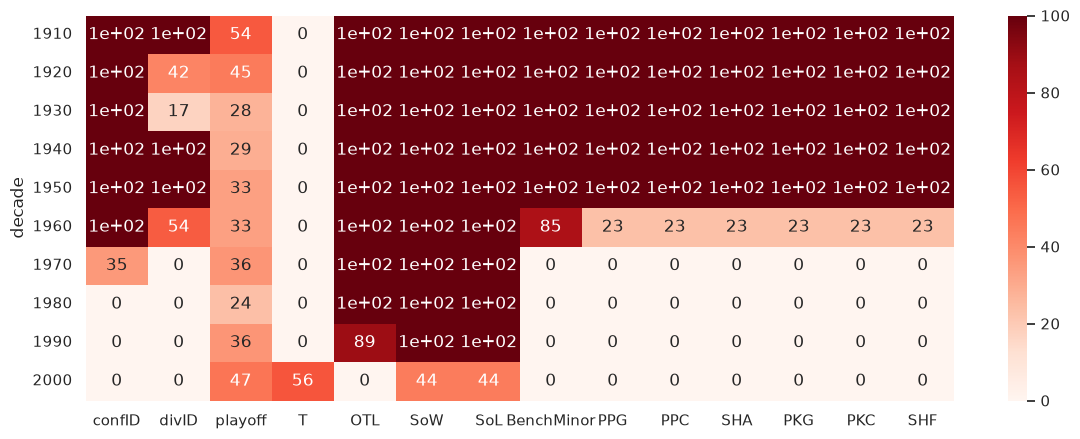

In [57]:
teams_nhl = q("""
    SELECT
        *
    FROM Teams
    WHERE lgID = "NHL"
""")


teams_nhl["decade"] = (teams_nhl["year"] // 10) * 10

teams_nhl_pct = (
    teams_nhl
        .drop(columns="decade")
        .isna()
        .groupby(teams_nhl["decade"])
        .mean() * 100
)

teams_nhl_pct = teams_nhl_pct.round(1)

teams_nhl_pct = teams_nhl_pct.loc[:, (teams_nhl_pct > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(teams_nhl_pct, annot=True, cmap="Reds")
plt.show()


**Result:** 14 of the 27 columns of `Teams` have missing values; the other 13 (games, wins, losses, goals, points, penalty minutes, rank…) are 100% complete in every decade.

| Column(s) | Missing until | Type | Explanation |
|---|---|---|---|
| `PPG`, `PPC`, `SHA`, `PKG`, `PKC`, `SHF` | 1962 (first season 1963) | not recorded | special-teams statistics only kept from 1963 |
| `BenchMinor` | 1968 (first season 1969) | not recorded | bench minor penalties only kept from 1969 |
| `confID` | 1973 | structural | conferences created in 1974 |
| `divID` | gaps until 1966 | structural | early seasons with a single group, no divisions |
| `OTL` | 1998 | structural | overtime-loss category created in 1999 |
| `T` | 2004 → NULL from 2005 | structural | ties abolished in 2005 |
| `SoW`, `SoL` | 2004 | structural | shootouts introduced in 2005 |
| `playoff` | every decade (24–55%) | meaningful | the team missed the playoffs |

**Only the special-teams columns are truly unknown**; every other missing value has a known meaning. **Action:** `T`, `OTL`, `SoW`, `SoL` → 0 where the event did not exist; `playoff` NULL → its own category ("missed the playoffs"); `confID`/`divID` are not used as features. Power-play and penalty-kill features are only available from **1963**.

#### % missing per column per decade (NHL `Scoring` and `Goalies`)

The same measure for the player tables, which will be aggregated into team features (e.g. shots, save percentage).

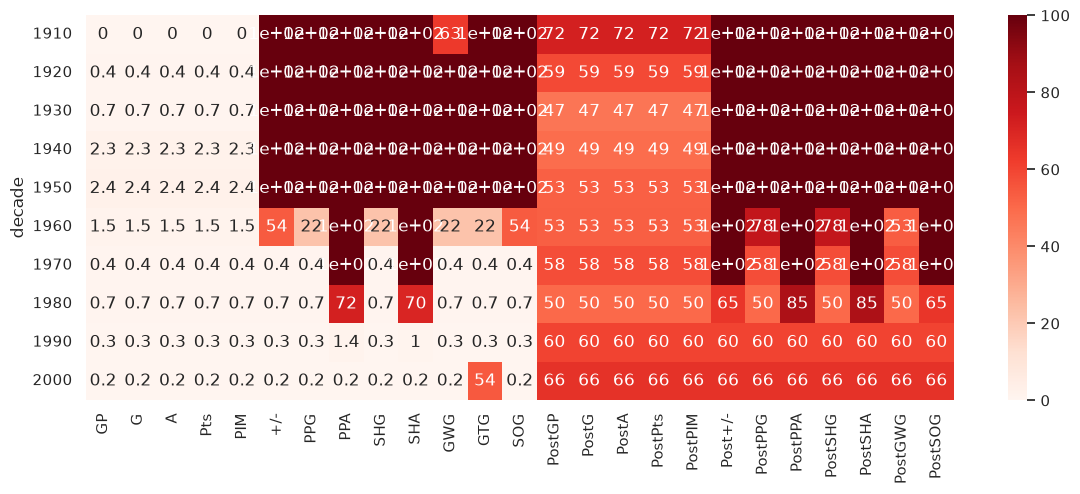

In [58]:
scoring_nhl = q("""
    SELECT
        *
    FROM Scoring
    WHERE lgID = "NHL"
""")


scoring_nhl["decade"] = (scoring_nhl["year"] // 10) * 10

scoring_nhl = (
    scoring_nhl
        .drop(columns="decade")
        .isna()
        .groupby(scoring_nhl["decade"])
        .mean() * 100
)

scoring_nhl = scoring_nhl.round(1)

scoring_nhl = scoring_nhl.loc[:, (scoring_nhl > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(scoring_nhl, annot=True, cmap="Reds")
plt.show()

**Result (`Scoring`):**
- **Basic statistics** (`GP`, `G`, `A`, `Pts`, `PIM`): under 2.5% missing in every decade. These 249 rows are players who **only played in the playoffs** for that team (247 of them have `PostGP`), so there is no regular-season line. Not a problem: summing per team ignores them.
- **Recorded from 1963:** `PPG`, `SHG`, `GWG`, `GTG`. **From 1967:** `SOG` (shots) and `+/-`. **From about 1987:** `PPA`, `SHA` (power-play and short-handed assists). All not recorded before.
- `GWG` is partly filled in the 1910s but then empty until 1963: an isolated early block, not usable.
- `GTG` (game-tying goals) is NULL in **every row from 2005**: structural, since a game can no longer end tied.
- `Post…` columns: 47–72% missing in every decade: meaningful, the player's team did not reach the playoffs (or the player did not play in them).

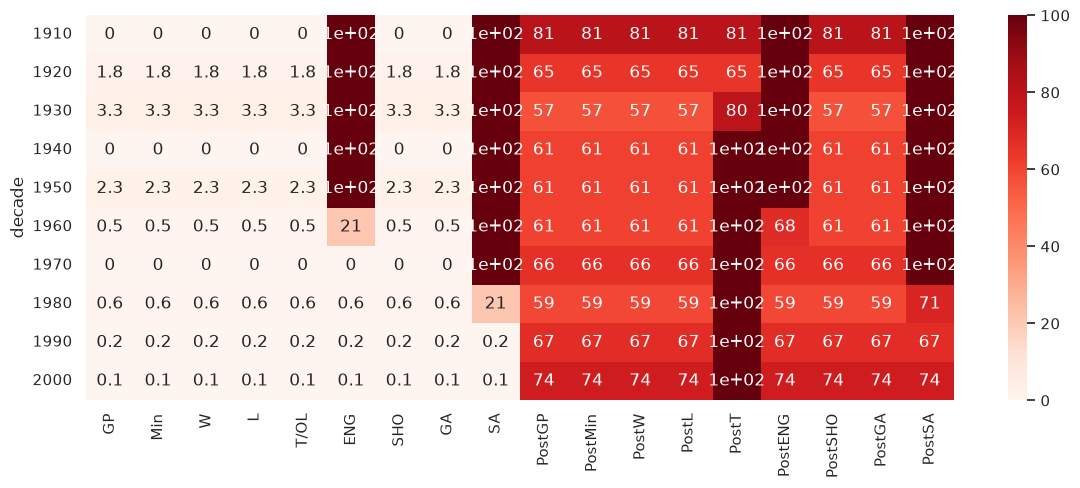

In [59]:
goalies_nhl = q("""
    SELECT
        *
    FROM Goalies
    WHERE lgID = "NHL"
""")


goalies_nhl["decade"] = (goalies_nhl["year"] // 10) * 10

goalies_nhl = (
    goalies_nhl
        .drop(columns="decade")
        .isna()
        .groupby(goalies_nhl["decade"])
        .mean() * 100
)

goalies_nhl = goalies_nhl.round(1)

goalies_nhl = goalies_nhl.loc[:, (goalies_nhl > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(goalies_nhl, annot=True, cmap="Reds")
plt.show()

**Result (`Goalies`):**
- **Basic statistics** (`GP`, `Min`, `W`, `L`, `GA`, `SHO`…): under 3.5% missing; the 18 rows are goalies who only played in the playoffs.
- `ENG` (empty-net goals) recorded from **1963**.
- **`SA` (shots against) recorded only from 1982** (21% missing in the 1980s, complete from 1990). Save percentage (1 − GA/SA), the usual measure of goalie quality, is therefore only possible from 1982.
- `PostT` is NULL in almost every row: there are no ties in the playoffs (overtime continues until a goal), so it is structural.

**Do the start years of team and player statistics line up?** Yes, in two steps: **1963** for special teams (`Teams.PPG`, `Scoring.PPG`, `Goalies.ENG`) and **1967** for shots and +/- (`Scoring.SOG`). Shots against for goalies come later, in **1982**.

#### Coaches (the table built in Data Integration)

The % missing per decade in our coach table. The result is stored in a new variable so the coach table `df` is not overwritten.

In [ ]:
coach_missing = (
    df
        .isna()
        .groupby((df["year"] // 10) * 10)
        .mean() * 100
)

coach_missing = coach_missing.round(1)
coach_missing.index.name = "decade"

coach_missing = coach_missing.loc[:, (coach_missing > 0).any()]
plt.figure(figsize=(6, 5))
sns.heatmap(coach_missing, annot=True, cmap="Reds")
plt.show()

**Result:** only 2 of the 19 columns have missing values:
- **`win_before_pct`** (232 rows): **planned**. It is NaN for rookie coaches, who have no previous games, and `is_rookie_coach` already marks them. It is 100% in the 1900s because every coach was a rookie in the first season of the data.
- **`age`** (56 rows): the coach has no `birthYear` in `Master`. **52 of the 56 are before 1930** (early coaches with poorly documented lives), 1 is an NHL coach in the 1930s, and the other 3 are WHA coaches from the 1970s (Brian Shaw, Steve Neves). In the NHL from 1940 on, the age is always known. (Missing birth month or day was already handled in Data Integration: the age is computed on 1 August.)

**Action:** keep `win_before_pct` as NaN together with `is_rookie_coach` (decided in Missing values). The missing ages disappear with Era Selection if the cut is after 1940; otherwise they have to be imputed.

#### Does every NHL team-season have a starting coach?

In [ ]:
nhl_team_seasons = q("""
    SELECT year, franchID
    FROM Teams
    WHERE lgID = "NHL"
""")

coach_coverage = nhl_team_seasons.merge(
    df[["year", "franchID"]], on=["year", "franchID"], how="left", indicator=True
)

print(coach_coverage["_merge"].value_counts())

**Result:** all **1,265** NHL team-seasons have exactly one row in the coach table (0 without a coach). **Action:** none; every row of the final table will have coach features.

#### Does every team-season have goalies in `Goalies`?

In [65]:
goalies_each_season = q("""
    SELECT 
        goa.year,
        goa.tmID,
        goa.lgID
    FROM Goalies goa
    JOIN Teams t
        ON goa.year = t.year 
        AND goa.tmID = t.tmID 
        AND goa.lgID = t.lgID
    GROUP BY
        goa.year,
        goa.tmID,
        goa.lgID

""")

goalies_each_season.shape

(1459, 3)

**Result:** 1,459 team-seasons have at least one goalie, the same as the number of rows in `Teams` (all leagues). Together with the result in Accuracy (every team-season has players in `Scoring`), **the player tables cover every team**: aggregating them to team level does not create missing rows.

#### Completeness summary

| Column(s) | Usable from | Type | Action |
|---|---|---|---|
| Team special teams (`PPG`, `PPC`, `PKG`, `PKC`, `SHA`, `SHF`) | 1963 | not recorded | only from 1963 |
| `Scoring.SOG` (shots), `+/-` | 1967 | not recorded | only from 1967 |
| `Goalies.SA` (save %) | 1982 | not recorded | only from 1982 |
| `T`, `OTL`, `SoW`, `SoL`, `GTG` | — | structural | count as 0 |
| `playoff`, `Post…` | — | meaningful | "missed the playoffs" category |
| `confID`, `divID` | — | structural | not used as features |
| Coach `win_before_pct` | — | planned (rookies) | keep NaN + `is_rookie_coach` |
| Coach `age` | complete in the NHL from 1940 | not recorded | solved by the era cut |
| Coverage (coach, players, goalies per team-season) | all seasons | — | none |

**Conclusion:** the basic statistics (games, wins, goals, points, penalties) are complete for the whole history, but the richer ones start in blocks. Completeness gives three **candidate start seasons** for Era Selection: **1963** (special teams), **1967** (shots and +/-; also the expansion from 6 to 12 teams) and **1982** (goalie shots against). The choice is a trade-off between more seasons and more features.

### Timeliness

*Does the data cover the period we need, and is every value we use already known when the prediction is made?*

Timeliness has two sides in this project:
1. **Time coverage:** do all tables reach the last season, without holes?
2. **Availability at prediction time:** the predictions are made **the day before season t starts**, so every feature must be known at that moment. Using anything that only becomes known during or after season t is **leakage**.

#### Time coverage of each table

In [ ]:
teams_years = q("""
    SELECT
        year
    FROM Teams
    ORDER BY year
""")

different_years = teams_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [79]:
coaches_years = q("""
    SELECT
        year
    FROM Coaches
    ORDER BY year
""")

different_years = coaches_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [80]:
scoring_years = q("""
    SELECT
        year
    FROM Scoring
    ORDER BY year
""")

different_years = scoring_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [81]:
goalies_years = q("""
    SELECT
        year
    FROM Goalies
    ORDER BY year
""")

different_years = goalies_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [82]:
awards_coaches_years = q("""
    SELECT
        year
    FROM AwardsCoaches
    ORDER BY year
""")

different_years = awards_coaches_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1930. The last year is: 2009.
There is different 53 years


In [83]:
teams_seasons = teams_years["year"].unique()

all_seasons = set(range(teams_seasons.min(), teams_seasons.max() + 1))
missing_seasons = sorted(all_seasons - set(teams_seasons))

print(f"Seasons missing in Teams between {teams_seasons.min()} and {teams_seasons.max()}: {missing_seasons}")

Seasons missing in Teams between 1909 and 2009: [2004]


In [84]:
q("""
    SELECT award, lgID, MIN(year) AS first_year, MAX(year) AS last_year, COUNT(*) AS n_awards
    FROM AwardsCoaches
    GROUP BY award, lgID
    ORDER BY first_year
""")

,award,lgID,first_year,last_year,n_awards
0,First Team All-Star,NHL,1930,1945,16
1,Second Team All-Star,NHL,1930,1945,16
2,Baldwin,WHA,1972,1973,2
3,Jack Adams,NHL,1973,2009,36
4,Schmertz,WHA,1974,1978,5


In [85]:
q("""
    SELECT year, COUNT(*) AS n_teams, SUM(playoff IS NOT NULL) AS n_playoff_teams
    FROM Teams
    WHERE lgID = "NHL" AND year >= 2000
    GROUP BY year
""")

,year,n_teams,n_playoff_teams
0,2000,30,16
1,2001,30,16
2,2002,30,16
3,2003,30,16
4,2005,30,16
5,2006,30,16
6,2007,30,16
7,2008,30,16
8,2009,30,16


**Result:**

| Table | First season | Last season | Distinct seasons |
|---|---|---|---|
| `Teams` | 1909 | 2009 | 100 |
| `Coaches` | 1909 | 2009 | 100 |
| `Scoring` | 1909 | 2009 | 100 |
| `Goalies` | 1909 | 2009 | 100 |
| `AwardsCoaches` | 1930 | 2009 | 53 |

- The main tables all cover **1909–2009**. 1909 to 2009 is 101 seasons, and the missing one is **2004**: the season was cancelled by the **lockout**. It is a real hole in time, already handled in Data Integration (season numbers built from the distinct years, so 2003 → 2005 counts as consecutive).
- **The last season is complete:** 2009 has the same 30 NHL teams and 16 playoff teams as the seasons before it, so it is a full season and can be used as the most recent test season.
- **`AwardsCoaches` has a gap in time.** The NHL "All-Star" coach awards exist only from **1930 to 1945**, then **no coach award at all from 1946 to 1972**, and the Jack Adams Award only from **1973** (plus two WHA awards in the 1970s). So `awards_before` = 0 means "no award won" from 1973 on, but in the 1950s and 1960s it means "**no award existed**". The feature does not mean the same thing across eras: a structural zero. **Action:** take it into account in Era Selection; if older seasons are kept, `awards_before` is only comparable from about 1973 on.

#### Is every feature known the day before season t?

Every column of the coach table, with what it is built from:

| Feature | Built from | Known before t? |
|---|---|---|
| `age` | birth date, measured at 1 August of season t | yes |
| `former_player` | the coach has a `playerID` in `Master` | yes, with a caveat (below) |
| `former_nhl_player` | the coach has a `firstNHL` in `Master` | **not always** (below) |
| `seasons_before`, `games_before`, `wins_before`, `losses_before`, `ties_before`, `postgames_before` | running totals of seasons **< t** (grouped shift) | yes (checked in Data Integration) |
| `win_before_pct` | the `_before` totals | yes |
| `is_rookie_coach` | `games_before` = 0 | yes |
| `awards_before` | awards of seasons **< t** (an award for season t is only given after the playoffs, so it counts from t+1) | yes (checked in Data Integration) |
| `tenure_before` | consecutive seasons with the franchise **before** t | yes (checked in Data Integration) |
| starting coach (`stint` = 1) | the coach who starts season t | yes, **assumption**: the starting coach is known before the first game |

**Caveat on the former-player flags.** They only check whether a playing career *exists* in `Master`, not whether it happened **before** season t. In **29** starting-coach seasons, the coach's first NHL season is season t itself or later: **player-coaches** in the early years (e.g. Newsy Lalonde and Art Ross in 1917), all **before 1928**. In those rows the flag uses information from the future. **Action:** the era cut removes them; if earlier seasons are kept, the flag must compare `firstNHL` with `year` (`firstNHL < year`).

**What must never be a feature:** anything from season t itself: the team's `W`, `GF`, `Pts`, `rank` or `playoff` of t, the coaches with stint > 1 in t, or the number of coaches of t (`n_stints`). These are exactly the targets (or contain them). **`n_stints` was dropped** for this reason. The same rule will hold for the team features: **team features for season t use only seasons ≤ t−1.**

#### Is old data still representative?

Timeliness is also about whether old data still describes the game we predict. Many things changed over the 100 seasons:
- **games per season:** 22 (1917) → 48 (1994 lockout season) → 80–84 (modern NHL);
- **number of teams:** 4 (1917) → 6 (1942–1966) → 12 (1967) → 30 (2000s);
- **rules:** overtime losses counted from 1999; ties abolished and the shootout introduced in 2005;
- **recorded statistics:** special teams from 1963, shots and +/- from 1967, goalie shots against from 1982 (see Completeness);
- **coach awards:** none from 1946 to 1972;
- **coaches:** player-coaches in the early years.

**Conclusion:** the older the season, the less it resembles the seasons we predict. This is the reason for the next step, **Sampling for the domain**.

**Consequence for evaluation:** because the data is ordered in time, train and test must be **split by season**: train on earlier seasons, test on later ones (e.g. the last seasons up to 2009). A random split would let the model learn from seasons after the one it predicts.

### Data Quality Summary

*Summary of the data quality assessment; details in each subsection.*

| Dimension | check | rows failing | explanation | action |
| --------- | ----- | ------------ | ----------- | ------ |
| 

## 3. Sampling for the domain: which seasons to use?

## Era Selection

## Missing values

## Outliers

## Redundancy

## Save the Final table